## **Application of Machine Learning Methods to Predict the Level of Building Damage in the Nepal Earthquake**

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving submission_format.csv to submission_format.csv
Saving test_values.csv to test_values.csv
Saving train_labels.csv to train_labels.csv
Saving train_values.csv to train_values.csv


In [ ]:
import pandas as pd
import numpy as np

train_values = pd.read_csv('train_values.csv')
train_labels = pd.read_csv('train_labels.csv')
test_values = pd.read_csv('test_values.csv')
submission_format = pd.read_csv('submission_format.csv')

In [ ]:
print("Train Values:", train_values.shape)
print("Train Labels:", train_labels.shape)
print("Test Values:", test_values.shape)
print("Submission Format:", submission_format.shape)

Train Values: (260601, 39)
Train Labels: (260601, 2)
Test Values: (86868, 39)
Submission Format: (86868, 2)


In [ ]:
#define function to displaying all row in data

def display_all(df):
    with pd.option_context('display.max_rows', None):
        with pd.option_context('display.max_columns', None):
            display(df)

In [ ]:
display_all(train_values.head())

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other
0,802906,6,487,12198,2,30,6,5,t,r,n,f,q,t,d,1,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0
1,28830,8,900,2812,2,10,8,7,o,r,n,x,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0
2,94947,21,363,8973,2,10,5,5,t,r,n,f,x,t,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0
3,590882,22,418,10694,2,10,6,5,t,r,n,f,x,s,d,0,1,0,0,0,0,1,1,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0
4,201944,11,131,1488,3,30,8,9,t,r,n,f,x,s,d,1,0,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0


In [ ]:
display_all(train_labels.head())

,building_id,damage_grade
0,802906,3
1,28830,2
2,94947,3
3,590882,2
4,201944,3


# **Merging Train Data**

In [ ]:
train_joined = pd.merge(train_values, train_labels)
display_all(train_joined.head())

,building_id,geo_level_1_id,geo_level_2_id,geo_level_3_id,count_floors_pre_eq,age,area_percentage,height_percentage,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,has_superstructure_adobe_mud,has_superstructure_mud_mortar_stone,has_superstructure_stone_flag,has_superstructure_cement_mortar_stone,has_superstructure_mud_mortar_brick,has_superstructure_cement_mortar_brick,has_superstructure_timber,has_superstructure_bamboo,has_superstructure_rc_non_engineered,has_superstructure_rc_engineered,has_superstructure_other,legal_ownership_status,count_families,has_secondary_use,has_secondary_use_agriculture,has_secondary_use_hotel,has_secondary_use_rental,has_secondary_use_institution,has_secondary_use_school,has_secondary_use_industry,has_secondary_use_health_post,has_secondary_use_gov_office,has_secondary_use_use_police,has_secondary_use_other,damage_grade
0,802906,6,487,12198,2,30,6,5,t,r,n,f,q,t,d,1,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
1,28830,8,900,2812,2,10,8,7,o,r,n,x,q,s,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
2,94947,21,363,8973,2,10,5,5,t,r,n,f,x,t,d,0,1,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3
3,590882,22,418,10694,2,10,6,5,t,r,n,f,x,s,d,0,1,0,0,0,0,1,1,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,2
4,201944,11,131,1488,3,30,8,9,t,r,n,f,x,s,d,1,0,0,0,0,0,0,0,0,0,0,v,1,0,0,0,0,0,0,0,0,0,0,0,3


# **Exploratory Data Analysis (EDA)**

In [ ]:
#summarize all column in train_joined data
def summary(df):
    print("summary")
    print("------------------------------")
    print(df.describe())
    print("------------------------------")
    print("columns types")
    print(df.dtypes)
    print("------------------------------")
    print("shape")
    print(df.shape)

summary(train_joined)

summary
------------------------------
        building_id  geo_level_1_id  geo_level_2_id  geo_level_3_id  \
count  2.606010e+05   260601.000000   260601.000000   260601.000000   
mean   5.256755e+05       13.900353      701.074685     6257.876148   
std    3.045450e+05        8.033617      412.710734     3646.369645   
min    4.000000e+00        0.000000        0.000000        0.000000   
25%    2.611900e+05        7.000000      350.000000     3073.000000   
50%    5.257570e+05       12.000000      702.000000     6270.000000   
75%    7.897620e+05       21.000000     1050.000000     9412.000000   
max    1.052934e+06       30.000000     1427.000000    12567.000000   

       count_floors_pre_eq            age  area_percentage  height_percentage  \
count        260601.000000  260601.000000    260601.000000      260601.000000   
mean              2.129723      26.535029         8.018051           5.434365   
std               0.727665      73.565937         4.392231           1.918418 

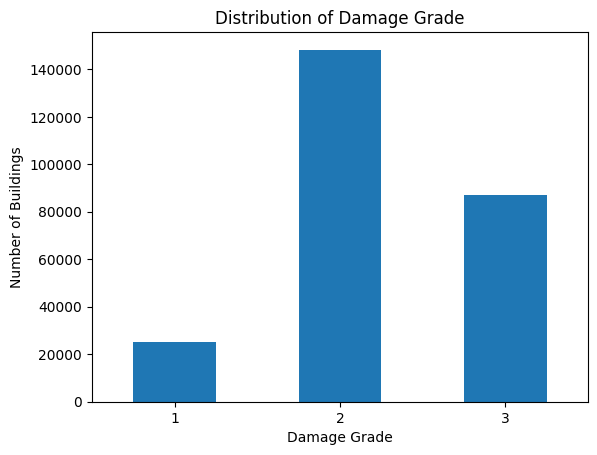

In [ ]:
# damage grade distribution
import matplotlib.pyplot as plt

train_joined["damage_grade"].value_counts().sort_index().plot(kind="bar")

plt.xlabel("Damage Grade")
plt.ylabel("Number of Buildings")
plt.title("Distribution of Damage Grade")
plt.xticks(rotation=0)
plt.show()

Based on the graph above, it can be concluded that the damage to the building is not balanced, where the least damage to the building is level 1 and the most is level 2.

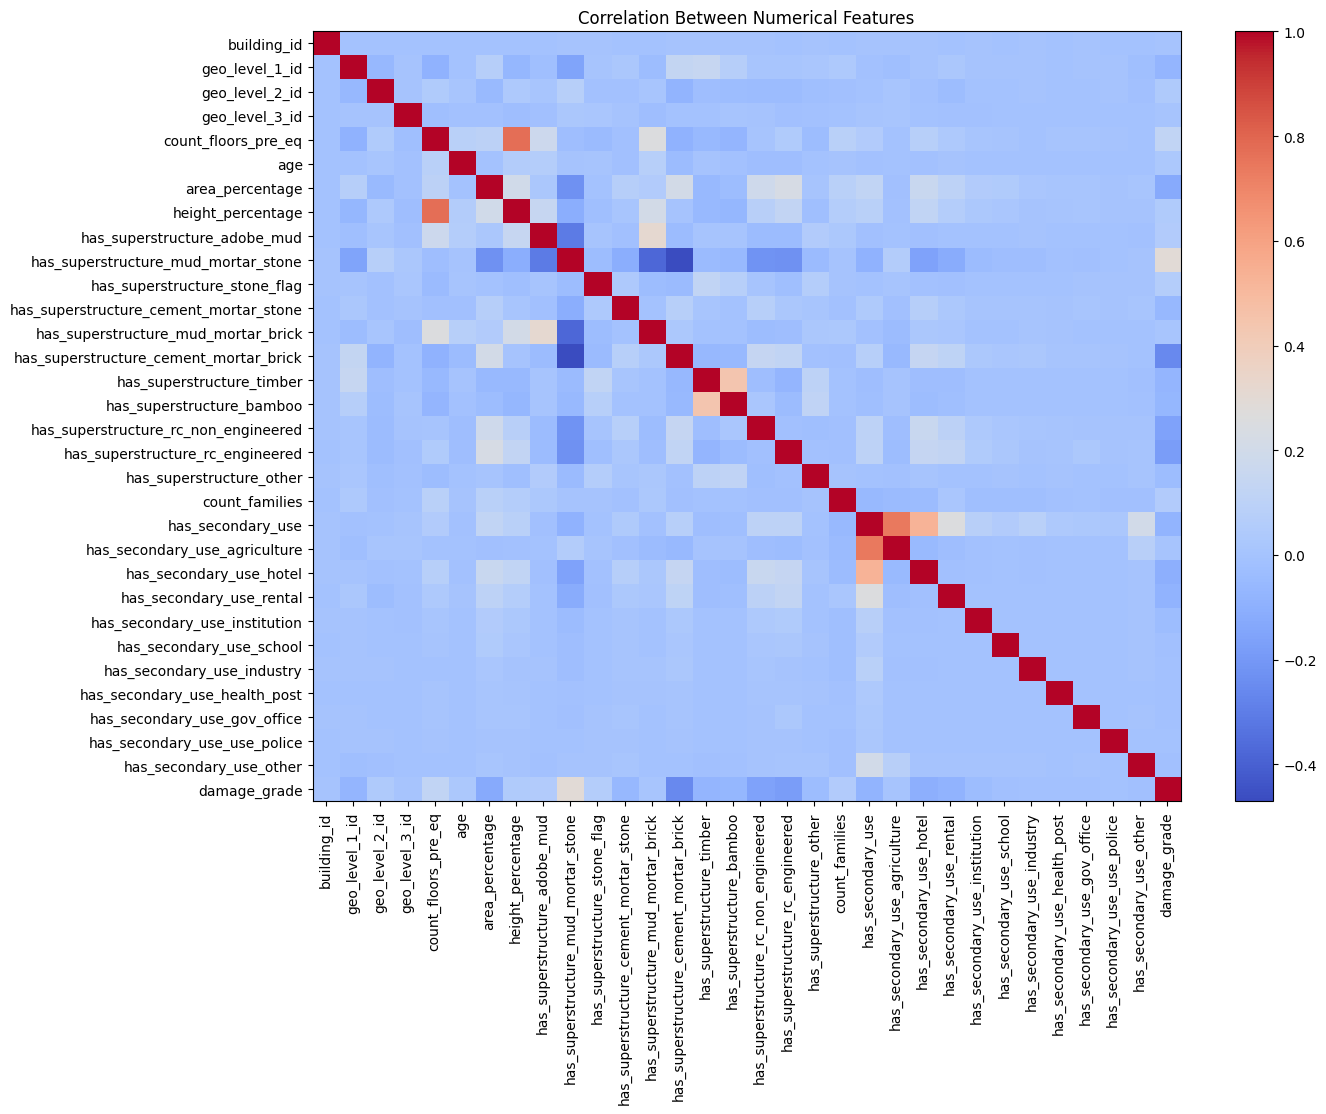

In [ ]:
#correlation between features
train_numerical = train_joined[
    train_joined.select_dtypes(exclude="object").columns]

corr = train_numerical.corr()

plt.figure(figsize=(14, 10))
plt.imshow(corr, cmap="coolwarm", aspect="auto")
plt.colorbar()

plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)

plt.title("Correlation Between Numerical Features")
plt.show()

In [ ]:
# which numerical features have the strongest relationship with damage grade
corr_damage = train_numerical.corr()["damage_grade"].sort_values(ascending=False)
print(corr_damage)

damage_grade                              1.000000
has_superstructure_mud_mortar_stone       0.291325
count_floors_pre_eq                       0.122308
has_superstructure_stone_flag             0.066039
count_families                            0.056151
has_superstructure_adobe_mud              0.055314
height_percentage                         0.048130
geo_level_2_id                            0.043161
age                                       0.029273
has_superstructure_mud_mortar_brick       0.014561
has_secondary_use_agriculture             0.011309
geo_level_3_id                            0.007932
building_id                               0.001063
has_secondary_use_use_police             -0.001656
has_secondary_use_health_post            -0.008543
has_secondary_use_gov_office             -0.009378
has_secondary_use_industry               -0.011024
has_secondary_use_school                 -0.011692
has_secondary_use_other                  -0.016334
has_secondary_use_institution  

Based on the graphs and data above, it can be seen that there are several positive correlations and some negative correlations to the building damage column but the correlation is not strong.

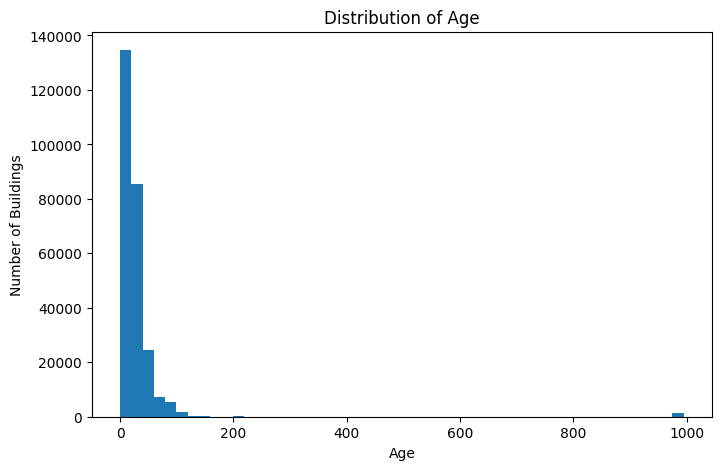

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(train_joined["age"], bins=50)
plt.xlabel("Age")
plt.ylabel("Number of Buildings")
plt.title("Distribution of Age")
plt.show()

Based on the distribution chart above, most buildings are between 0 to 100 years old, but there are some buildings that are more than 100 years old.


 (26041, 40)


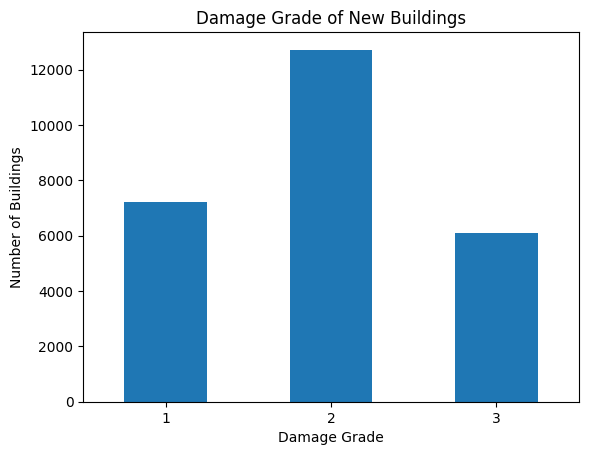

In [ ]:
#Damage grade for buildings with age = 0
new_building = train_joined[train_joined["age"] == 0]
print("\n",new_building.shape)

new_building["damage_grade"].value_counts().sort_index().plot(kind="bar")

plt.xlabel("Damage Grade")
plt.ylabel("Number of Buildings")
plt.title("Damage Grade of New Buildings")
plt.xticks(rotation=0)

plt.show()

(2124, 40)


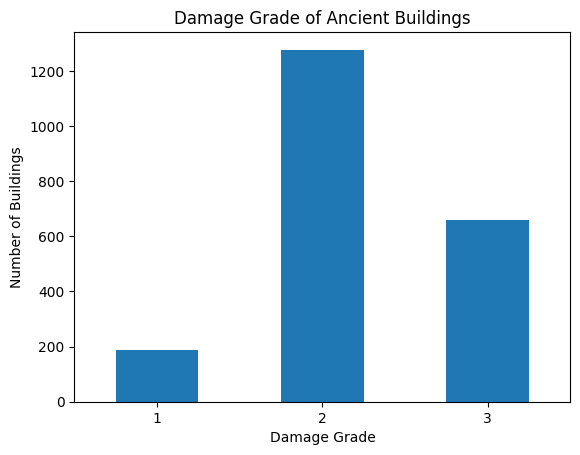

In [ ]:
# Damage grade for very old buildings (age > 100)
ancient_building = train_joined[train_joined["age"] > 100]
print(ancient_building.shape)


ancient_building["damage_grade"].value_counts().sort_index().plot(kind="bar")
plt.xlabel("Damage Grade")
plt.ylabel("Number of Buildings")
plt.title("Damage Grade of Ancient Buildings")
plt.xticks(rotation=0)
plt.show()

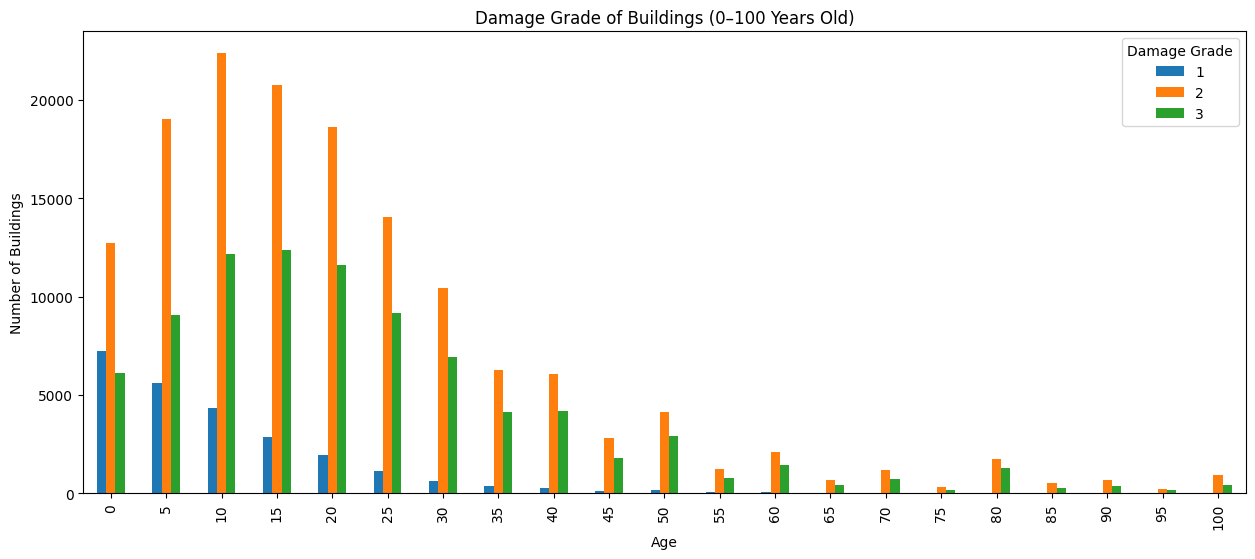

In [ ]:
# Damage grade vs age for buildings aged 0–100
other_building = train_joined[train_joined["age"] <= 100]

pd.crosstab(
    other_building["age"],
    other_building["damage_grade"]
).plot(kind="bar", figsize=(15, 6))

plt.xlabel("Age")
plt.ylabel("Number of Buildings")
plt.title("Damage Grade of Buildings (0–100 Years Old)")
plt.legend(title="Damage Grade")

plt.show()

Building damages level looks very imbalanced. As we can see that as the building ages, the first level damage will be less and only new buildings have a damage rate of one greater than a level of three damage.

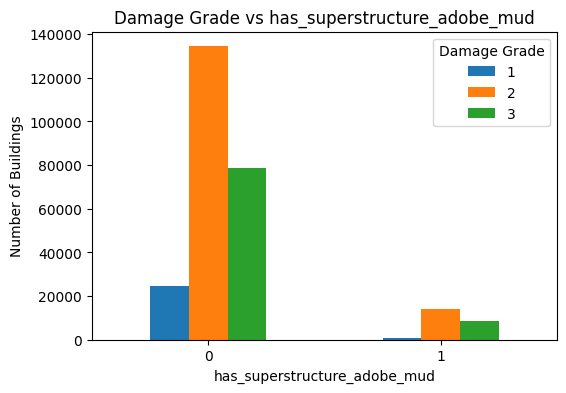

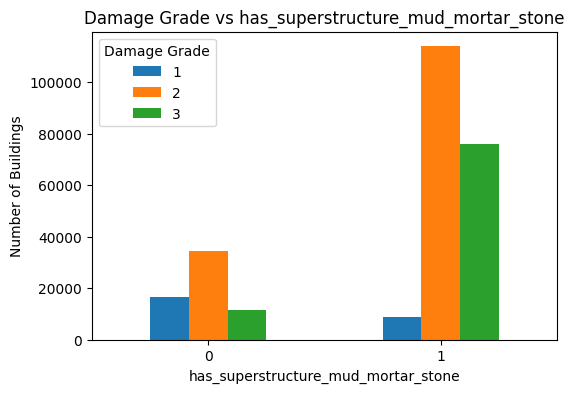

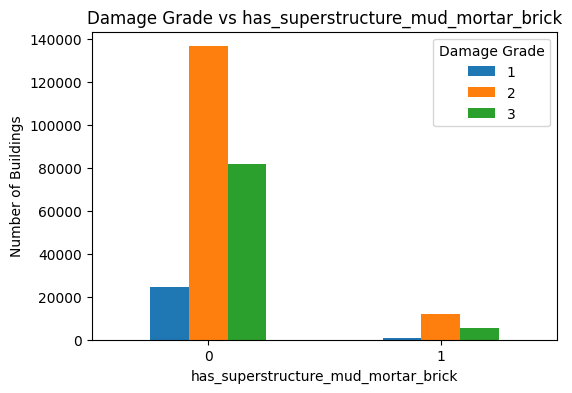

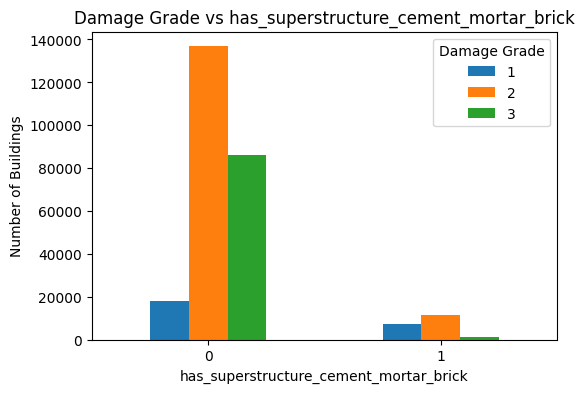

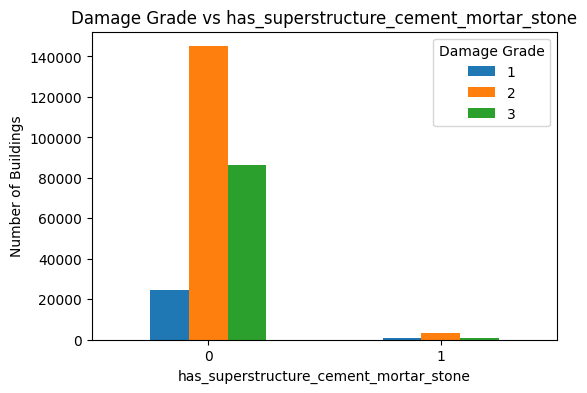

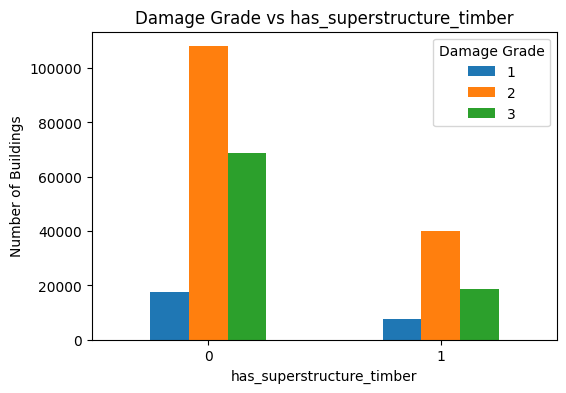

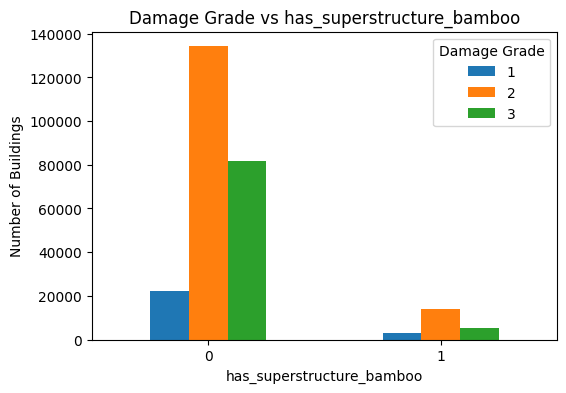

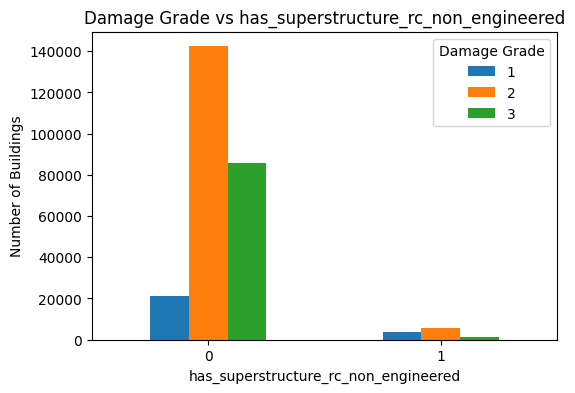

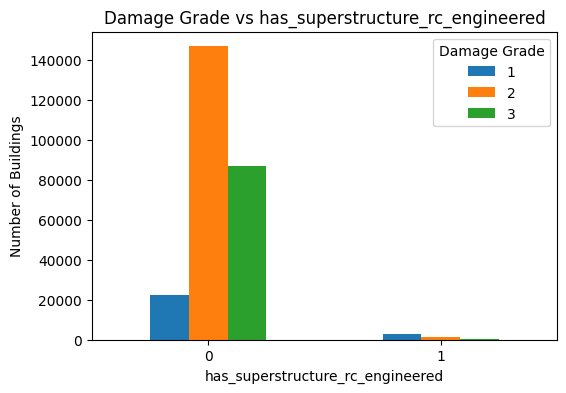

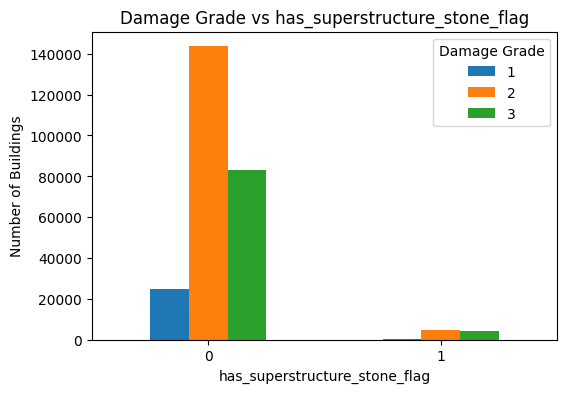

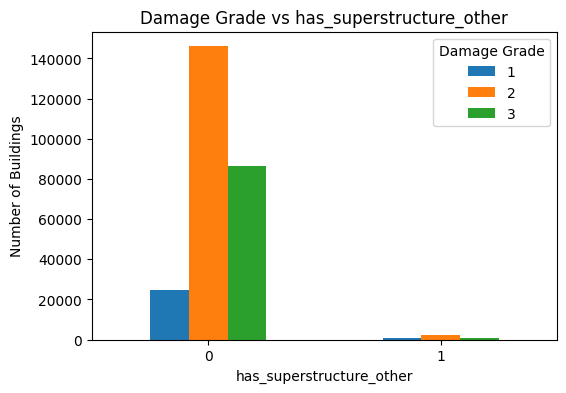

In [ ]:
cols = [
    'has_superstructure_adobe_mud',
    'has_superstructure_mud_mortar_stone',
    'has_superstructure_mud_mortar_brick',
    'has_superstructure_cement_mortar_brick',
    'has_superstructure_cement_mortar_stone',
    'has_superstructure_timber',
    'has_superstructure_bamboo',
    'has_superstructure_rc_non_engineered',
    'has_superstructure_rc_engineered',
    'has_superstructure_stone_flag',
    'has_superstructure_other'
]

for col in cols:
    pd.crosstab(
        train_joined[col],
        train_joined["damage_grade"]
    ).plot(kind="bar", figsize=(6, 4))

    plt.xlabel(col)
    plt.ylabel("Number of Buildings")
    plt.title("Damage Grade vs " + col)
    plt.legend(title="Damage Grade")
    plt.xticks(rotation=0)

    plt.show()

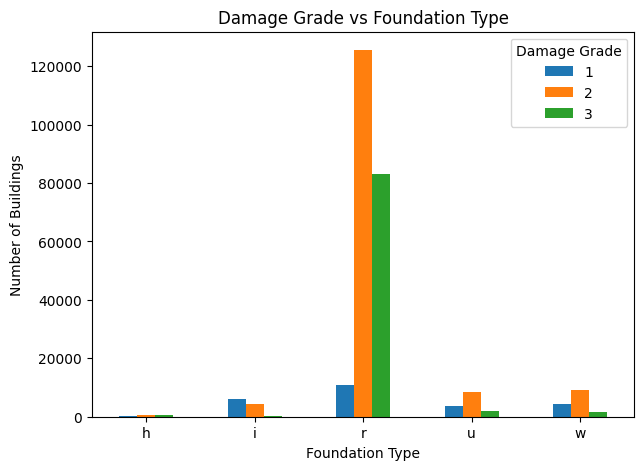

In [ ]:
# Foundation type vs damage grade
pd.crosstab(
    train_joined["foundation_type"],
    train_joined["damage_grade"]
).plot(kind="bar", figsize=(7, 5))

plt.xlabel("Foundation Type")
plt.ylabel("Number of Buildings")
plt.title("Damage Grade vs Foundation Type")
plt.legend(title="Damage Grade")
plt.xticks(rotation=0)

plt.show()

Foundation type r is the type of foundation that is most widely used and has the most damage to the third degree, while the type of foundation i is the type of foundation that has the least percentage of damage to the third degree compared to other types of foundations.

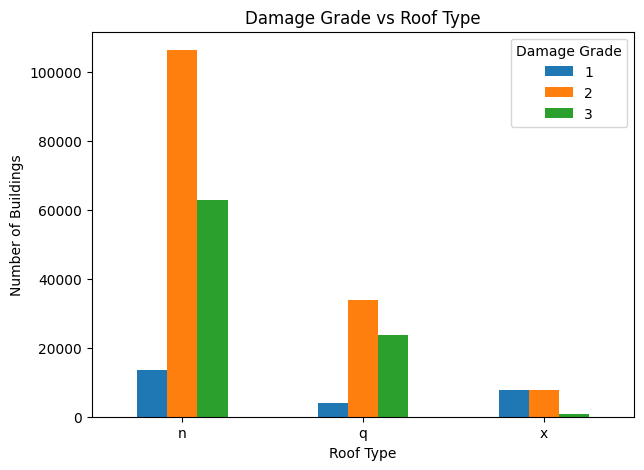

In [ ]:
# Roof type vs damage grade
pd.crosstab(
    train_joined["roof_type"],
    train_joined["damage_grade"]
).plot(kind="bar", figsize=(7, 5))

plt.xlabel("Roof Type")
plt.ylabel("Number of Buildings")
plt.title("Damage Grade vs Roof Type")
plt.legend(title="Damage Grade")
plt.xticks(rotation=0)

plt.show()

Roof type n is the type of roof that is most often used in the analyzed buildings where the level of damage is dominated by second-level damage, while based on the graph above, the strongest type of roof is type x because there is almost no third-level damage to this type of roof.

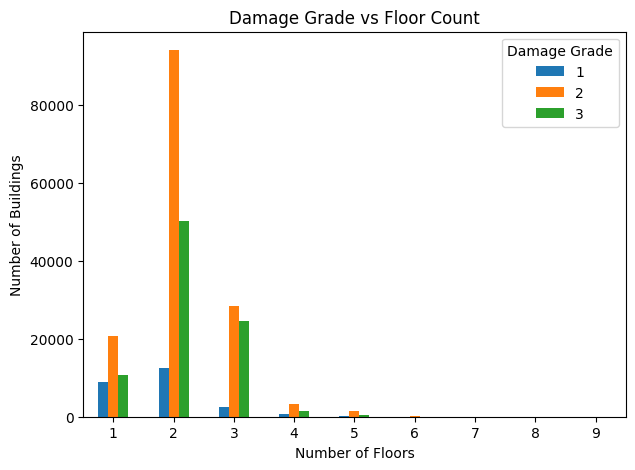

In [ ]:
# Number of floors vs damage grade
pd.crosstab(
    train_joined["count_floors_pre_eq"],
    train_joined["damage_grade"]
).plot(kind="bar", figsize=(7, 5))

plt.xlabel("Number of Floors")
plt.ylabel("Number of Buildings")
plt.title("Damage Grade vs Floor Count")
plt.legend(title="Damage Grade")
plt.xticks(rotation=0)

plt.show()

Based on the graph above, it can be concluded that the average building has two floors where taller buildings have a higher percentage of third-level damage and less first-level damage. This indicates that the taller the building, the greater the chance that the building will have a higher level of damage.

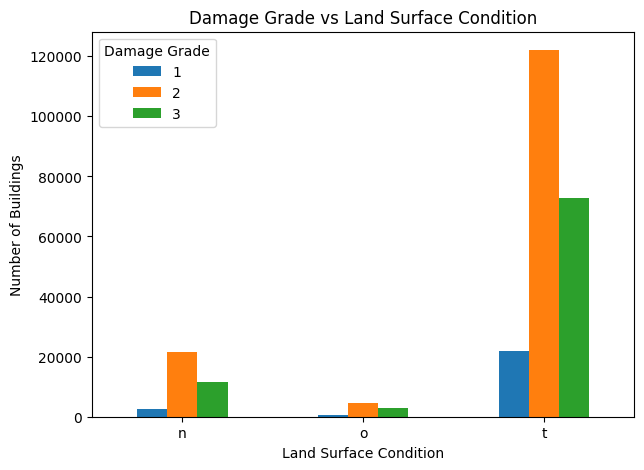

In [ ]:
# Land surface condition vs damage grade
pd.crosstab(
    train_joined["land_surface_condition"],
    train_joined["damage_grade"]
).plot(kind="bar", figsize=(7, 5))

plt.xlabel("Land Surface Condition")
plt.ylabel("Number of Buildings")
plt.title("Damage Grade vs Land Surface Condition")
plt.legend(title="Damage Grade")
plt.xticks(rotation=0)

plt.show()

Surface soil conditions are dominated by t conditions where the highest level of damage is at level two and soil conditions are at least o soil conditions where there is only second-level damage and third-level damage which can be concluded that the soil conditions are o worse than other soil conditions.

# **Data Cleaning**

In [ ]:
# Missing values in training data
missing_train = train_joined.isnull().sum()

missing_train = pd.DataFrame({
    "Rows With Missing Value": missing_train,
    "Percentage (%)": (missing_train / len(train_joined) * 100).round(2)
})

missing_train.sort_values("Percentage (%)", ascending=False)

,Rows With Missing Value,Percentage (%)
building_id,0,0.0
geo_level_1_id,0,0.0
geo_level_2_id,0,0.0
geo_level_3_id,0,0.0
count_floors_pre_eq,0,0.0
age,0,0.0
area_percentage,0,0.0
height_percentage,0,0.0
land_surface_condition,0,0.0
foundation_type,0,0.0


In [ ]:
# Missing values in test data
missing_test = test_values.isnull().sum()

missing_test = pd.DataFrame({
    "Rows With Missing Value": missing_test,
    "Percentage (%)": (missing_test / len(test_values) * 100).round(2)
})

missing_test.sort_values("Percentage (%)", ascending=False)

,Rows With Missing Value,Percentage (%)
building_id,0,0.0
geo_level_1_id,0,0.0
geo_level_2_id,0,0.0
geo_level_3_id,0,0.0
count_floors_pre_eq,0,0.0
age,0,0.0
area_percentage,0,0.0
height_percentage,0,0.0
land_surface_condition,0,0.0
foundation_type,0,0.0


Conclusion : The quality of the available data is quite good, There are no missing values in train and test dataset

In [ ]:
# Check for columns with only one unique value
for col in train_joined.columns:
    if train_joined[col].nunique() == 1:
        print(col)

Conclusion : There are no columns with single unique values in train and test dataset, We can continue the analysis process to the creation of a data model.

In [ ]:
# Separate features and target
X = train_joined.drop(columns=["building_id", "damage_grade"])
y = train_joined["damage_grade"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (260601, 38)
y shape: (260601,)


In [ ]:
# Check class distribution
print("Number of buildings in each damage grade:")
print(y.value_counts().sort_index())

print("\nPercentage of buildings in each damage grade:")
print(
    y.value_counts(normalize=True)
     .sort_index()
     .mul(100)
     .round(2)
)

Number of buildings in each damage grade:
damage_grade
1     25124
2    148259
3     87218
Name: count, dtype: int64

Percentage of buildings in each damage grade:
damage_grade
1     9.64
2    56.89
3    33.47
Name: proportion, dtype: float64


# **Data Splitting**

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.1,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("y_train shape:", y_train.shape)
print("y_val shape:", y_val.shape)

X_train shape: (234540, 38)
X_val shape: (26061, 38)
y_train shape: (234540,)
y_val shape: (26061,)


# **Preprocessing**

In [ ]:
# Identify numerical and categorical columns

numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X_train.select_dtypes(
    include=["object"]
).columns

print("Number of numerical features:", len(numerical_features))
print("Number of categorical features:", len(categorical_features))

print("\nNumerical features:")
print(list(numerical_features))

print("\nCategorical features:")
print(list(categorical_features))

Number of numerical features: 30
Number of categorical features: 8

Numerical features:
['geo_level_1_id', 'geo_level_2_id', 'geo_level_3_id', 'count_floors_pre_eq', 'age', 'area_percentage', 'height_percentage', 'has_superstructure_adobe_mud', 'has_superstructure_mud_mortar_stone', 'has_superstructure_stone_flag', 'has_superstructure_cement_mortar_stone', 'has_superstructure_mud_mortar_brick', 'has_superstructure_cement_mortar_brick', 'has_superstructure_timber', 'has_superstructure_bamboo', 'has_superstructure_rc_non_engineered', 'has_superstructure_rc_engineered', 'has_superstructure_other', 'count_families', 'has_secondary_use', 'has_secondary_use_agriculture', 'has_secondary_use_hotel', 'has_secondary_use_rental', 'has_secondary_use_institution', 'has_secondary_use_school', 'has_secondary_use_industry', 'has_secondary_use_health_post', 'has_secondary_use_gov_office', 'has_secondary_use_use_police', 'has_secondary_use_other']

Categorical features:
['land_surface_condition', 'found

In [ ]:
# Create the preprocessing pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [ ]:
# Fit preprocessing only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same preprocessing to validation data
X_val_processed = preprocessor.transform(X_val)

print("X_train_processed shape:", X_train_processed.shape)
print("X_val_processed shape:", X_val_processed.shape)

X_train_processed shape: (234540, 68)
X_val_processed shape: (26061, 68)


In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif

selector = SelectKBest(
    score_func=f_classif,
    k=20)

X_train_selected = selector.fit_transform(
    X_train_processed,
    y_train)

X_val_selected = selector.transform(
    X_val_processed)

print("Original number of features:", X_train_processed.shape[1])
print("Selected number of features:", X_train_selected.shape[1])

Original number of features: 68
Selected number of features: 20


In [ ]:
# See which features were selected
selected_mask = selector.get_support()
feature_names = preprocessor.get_feature_names_out()
selected_features = feature_names[selected_mask]

print("Selected features:")
for feature in selected_features:
    print(feature)

Selected features:
num__geo_level_1_id
num__count_floors_pre_eq
num__area_percentage
num__has_superstructure_mud_mortar_stone
num__has_superstructure_cement_mortar_brick
num__has_superstructure_rc_non_engineered
num__has_superstructure_rc_engineered
num__has_secondary_use_hotel
num__has_secondary_use_rental
cat__foundation_type_i
cat__foundation_type_r
cat__foundation_type_u
cat__foundation_type_w
cat__roof_type_n
cat__roof_type_x
cat__ground_floor_type_f
cat__ground_floor_type_v
cat__other_floor_type_j
cat__other_floor_type_q
cat__other_floor_type_s


In [ ]:
import pandas as pd
pd.DataFrame({
    "Feature": feature_names
}).to_csv("feature_names.csv", index=False)

print("Feature names saved:", len(feature_names))

Feature names saved: 68


In [ ]:
# Class distribution after splitting
print("Training set:")
print(
    y_train.value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2))

print("\nValidation set:")
print(
    y_val.value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2))

Training set:
damage_grade
1     9.64
2    56.89
3    33.47
Name: proportion, dtype: float64

Validation set:
damage_grade
1     9.64
2    56.89
3    33.47
Name: proportion, dtype: float64


In [ ]:
# Original feature set
X_train_original = X_train_processed
X_val_original = X_val_processed

# Feature-selected set
X_train_selected = X_train_selected
X_val_selected = X_val_selected

print("Original:", X_train_original.shape)
print("Selected:", X_train_selected.shape)

Original: (234540, 68)
Selected: (234540, 20)


# **Class-Imbalance Handling**

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

classes = np.unique(y_train)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weight_dict = dict(zip(classes, class_weights))

print("Class weights:")
print(class_weight_dict)

Class weights:
{np.int64(1): np.float64(3.4576091283003847), np.int64(2): np.float64(0.5859120307570092), np.int64(3): np.float64(0.9959743171626579)}


# **Prepare the four experiment configurations**

In [ ]:
# Experiment 1: Original features + No class balancing
X_train_exp1 = X_train_original
X_val_exp1 = X_val_original

# Experiment 2: Selected features + No class balancing
X_train_exp2 = X_train_selected
X_val_exp2 = X_val_selected

# Experiment 3: Original features + Class balancing
X_train_exp3 = X_train_original
X_val_exp3 = X_val_original

# Experiment 4: Selected features + Class balancing
X_train_exp4 = X_train_selected
X_val_exp4 = X_val_selected

# **Prepare Test Values**

In [ ]:
# Removing building_id
X_test = test_values.drop(columns=["building_id"])
print("X_test shape:", X_test.shape)

# Applying Preprocessing to test data
X_test_processed = preprocessor.transform(X_test)
print("X_test_processed shape:", X_test_processed.shape)

# Apply the same feature selection
X_test_selected = selector.transform(X_test_processed)
print("X_test_selected shape:", X_test_selected.shape)

X_test shape: (86868, 38)
X_test_processed shape: (86868, 68)
X_test_selected shape: (86868, 20)


# **Saving Prepared Datasets for medeling and evaluation**

In [ ]:
import json

with open("class_weights.json", "w") as f:
    json.dump(
        {str(k): float(v) for k, v in class_weight_dict.items()},
        f
    )

print("Class weights saved successfully.")

Class weights saved successfully.


In [ ]:
pd.DataFrame(X_train_original).to_csv("X_train_original.csv", index=False)
pd.DataFrame(X_val_original).to_csv("X_val_original.csv", index=False)

pd.DataFrame(X_train_selected).to_csv("X_train_selected.csv", index=False)
pd.DataFrame(X_val_selected).to_csv("X_val_selected.csv", index=False)

pd.DataFrame(X_test_processed).to_csv("X_test_original.csv", index=False)
pd.DataFrame(X_test_selected).to_csv("X_test_selected.csv", index=False)

y_train.to_csv("y_train.csv", index=False)
y_val.to_csv("y_val.csv", index=False)